In [19]:
%%html
<style>
div.optional {
    display: block;
    background-color: #d7e2ff;
    border-color: #d7e2ff;
    border-left: 5px solid #d7e2ff;
    padding: 0.5em;
}
div.advanced {
    display: block;
    background-color: #fff4d7;
    border-color: #fff4d7;
    border-left: 5px solid #fff4d7;
    padding: 0.5em;
}
</style>

In [20]:
%matplotlib inline
%precision 6
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as sl
from pprint import pprint

# if you get a ffmpeg error when creating movies try `conda install -c conda-forge ffmpeg` and restart Anaconda

# Computational Mathematics  <a class="tocSkip">

## Linear Algebra 2  <a class="tocSkip">
    
### (more linear algebra and some of its applications)  <a class="tocSkip">

## Learning outcomes  <a class="tocSkip">
    
    
1. To further our understanding of linear algebra from a geometrical perspective.

<br>
    
2. To extend the previous lecture's discussion to the topic of eigenvalues and eigenvectors.

<br>
    
3. To appreciate the existence and uniqueness of eigenvalues/vectors, more on bases, and matrix diagonalisation, as well as the SVD.

<br>
    
4. To give you some exposure to how these ideas can be used to analyse and solve systems of ODEs [including material in the supplementary notebook(s)].
    
    
<br><br>
    
Notice that much of the content in this lecture is optional. If eigenvalues/vectors are new to you, just focus on their geometrical interpretation and use in the factorisation/diagonalisation of matrices (sections 2-5), and then a very general  appreciation (but don't worry about the details) of them being of significant value for many applications (section 6), and can be generalised to equally useful analogues in the case of non-square matrices (section 7).

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Introductory-comments" data-toc-modified-id="Introductory-comments-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Introductory comments</a></span></li><li><span><a href="#Geometric-Interpretation-of-Linear-Transformations-(continued)" data-toc-modified-id="Geometric-Interpretation-of-Linear-Transformations-(continued)-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Geometric Interpretation of Linear Transformations (continued)</a></span><ul class="toc-item"><li><span><a href="#Visualizing-the-transformation:-unit-circle-to-ellipse" data-toc-modified-id="Visualizing-the-transformation:-unit-circle-to-ellipse-2.1"><span class="toc-item-num">2.1&nbsp;&nbsp;</span>Visualizing the transformation: unit circle to ellipse</a></span></li><li><span><a href="#Eigenvectors-and-eigenvalues:-the-transformation's-&quot;natural-axes&quot;" data-toc-modified-id="Eigenvectors-and-eigenvalues:-the-transformation's-&quot;natural-axes&quot;-2.2"><span class="toc-item-num">2.2&nbsp;&nbsp;</span>Eigenvectors and eigenvalues: the transformation's "natural axes"</a></span></li><li><span><a href="#The-special-case-of-symmetric-matrices" data-toc-modified-id="The-special-case-of-symmetric-matrices-2.3"><span class="toc-item-num">2.3&nbsp;&nbsp;</span>The special case of symmetric matrices</a></span></li><li><span><a href="#Transforming-a-vector-vs.-changing-basis" data-toc-modified-id="Transforming-a-vector-vs.-changing-basis-2.4"><span class="toc-item-num">2.4&nbsp;&nbsp;</span>Transforming a vector vs. changing basis</a></span><ul class="toc-item"><li><span><a href="#Applying-a-transformation" data-toc-modified-id="Applying-a-transformation-2.4.1"><span class="toc-item-num">2.4.1&nbsp;&nbsp;</span>Applying a transformation</a></span></li><li><span><a href="#Changing-the-basis" data-toc-modified-id="Changing-the-basis-2.4.2"><span class="toc-item-num">2.4.2&nbsp;&nbsp;</span>Changing the basis</a></span></li></ul></li><li><span><a href="#Transformation-with-respect-to-a-different-basis-[*]" data-toc-modified-id="Transformation-with-respect-to-a-different-basis-[*]-2.5"><span class="toc-item-num">2.5&nbsp;&nbsp;</span>Transformation with respect to a different basis [*]</a></span></li></ul></li><li><span><a href="#Eigenvalues-and-eigenvectors" data-toc-modified-id="Eigenvalues-and-eigenvectors-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Eigenvalues and eigenvectors</a></span><ul class="toc-item"><li><span><a href="#How-to-find-eigenvalues-and-eigenvectors" data-toc-modified-id="How-to-find-eigenvalues-and-eigenvectors-3.1"><span class="toc-item-num">3.1&nbsp;&nbsp;</span>How to find eigenvalues and eigenvectors</a></span></li><li><span><a href="#Projecting-(onto-eigenvectors)" data-toc-modified-id="Projecting-(onto-eigenvectors)-3.2"><span class="toc-item-num">3.2&nbsp;&nbsp;</span>Projecting (onto eigenvectors)</a></span></li></ul></li><li><span><a href="#The-determinant-again,-and-its-use-in-finding-eigenvalues" data-toc-modified-id="The-determinant-again,-and-its-use-in-finding-eigenvalues-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>The determinant again, and its use in finding eigenvalues</a></span><ul class="toc-item"><li><span><a href="#An-example-eigenvalue-problem" data-toc-modified-id="An-example-eigenvalue-problem-4.1"><span class="toc-item-num">4.1&nbsp;&nbsp;</span>An example eigenvalue problem</a></span></li><li><span><a href="#What-does-linear-(in)dependence-mean?" data-toc-modified-id="What-does-linear-(in)dependence-mean?-4.2"><span class="toc-item-num">4.2&nbsp;&nbsp;</span>What does linear (in)dependence mean?</a></span></li><li><span><a href="#Repeated-eigenvalues---algebraic-&amp;-geometric-multiplicity" data-toc-modified-id="Repeated-eigenvalues---algebraic-&amp;-geometric-multiplicity-4.3"><span class="toc-item-num">4.3&nbsp;&nbsp;</span>Repeated eigenvalues - algebraic &amp; geometric multiplicity</a></span></li><li><span><a href="#Some-useful-theoretical-results-about-eigenvalues/vectors" data-toc-modified-id="Some-useful-theoretical-results-about-eigenvalues/vectors-4.4"><span class="toc-item-num">4.4&nbsp;&nbsp;</span>Some useful theoretical results about eigenvalues/vectors</a></span></li><li><span><a href="#Symmetric-Positive-Definite-(SPD)-matrices-[*]" data-toc-modified-id="Symmetric-Positive-Definite-(SPD)-matrices-[*]-4.5"><span class="toc-item-num">4.5&nbsp;&nbsp;</span>Symmetric Positive-Definite (SPD) matrices [*]</a></span><ul class="toc-item"><li><span><a href="#Diagonal-dominance" data-toc-modified-id="Diagonal-dominance-4.5.1"><span class="toc-item-num">4.5.1&nbsp;&nbsp;</span>Diagonal dominance</a></span></li></ul></li></ul></li><li><span><a href="#Matrix-diagonalisation" data-toc-modified-id="Matrix-diagonalisation-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Matrix diagonalisation</a></span><ul class="toc-item"><li><span><a href="#Symmetric-real-matrices" data-toc-modified-id="Symmetric-real-matrices-5.1"><span class="toc-item-num">5.1&nbsp;&nbsp;</span>Symmetric real matrices</a></span></li><li><span><a href="#Orthogonal-Matrices:-Rotations-and-Reflections" data-toc-modified-id="Orthogonal-Matrices:-Rotations-and-Reflections-5.2"><span class="toc-item-num">5.2&nbsp;&nbsp;</span>Orthogonal Matrices: Rotations and Reflections</a></span><ul class="toc-item"><li><span><a href="#Properties-and-Geometric-Interpretation" data-toc-modified-id="Properties-and-Geometric-Interpretation-5.2.1"><span class="toc-item-num">5.2.1&nbsp;&nbsp;</span>Properties and Geometric Interpretation</a></span></li><li><span><a href="#Relevance" data-toc-modified-id="Relevance-5.2.2"><span class="toc-item-num">5.2.2&nbsp;&nbsp;</span>Relevance</a></span></li></ul></li><li><span><a href="#When-is-a-matrix-diagonalisable?-[*]" data-toc-modified-id="When-is-a-matrix-diagonalisable?-[*]-5.3"><span class="toc-item-num">5.3&nbsp;&nbsp;</span>When is a matrix diagonalisable? [*]</a></span><ul class="toc-item"><li><span><a href="#The-details" data-toc-modified-id="The-details-5.3.1"><span class="toc-item-num">5.3.1&nbsp;&nbsp;</span>The details</a></span></li><li><span><a href="#An-example" data-toc-modified-id="An-example-5.3.2"><span class="toc-item-num">5.3.2&nbsp;&nbsp;</span>An example</a></span></li></ul></li><li><span><a href="#A-geometrical-interpretation-of-matrix-multiplication-using-matrix-diagonalisation" data-toc-modified-id="A-geometrical-interpretation-of-matrix-multiplication-using-matrix-diagonalisation-5.4"><span class="toc-item-num">5.4&nbsp;&nbsp;</span>A geometrical interpretation of matrix multiplication using matrix diagonalisation</a></span></li></ul></li><li><span><a href="#Some-applications-of-eigen-values/vectors" data-toc-modified-id="Some-applications-of-eigen-values/vectors-6"><span class="toc-item-num">6&nbsp;&nbsp;</span>Some applications of eigen-values/vectors</a></span></li><li><span><a href="#Singular-Value-Decomposition-(SVD)" data-toc-modified-id="Singular-Value-Decomposition-(SVD)-7"><span class="toc-item-num">7&nbsp;&nbsp;</span>Singular Value Decomposition (SVD)</a></span><ul class="toc-item"><li><span><a href="#Geometric-interpretation:-rotation--&gt;-scaling--&gt;-rotation" data-toc-modified-id="Geometric-interpretation:-rotation--&gt;-scaling--&gt;-rotation-7.1"><span class="toc-item-num">7.1&nbsp;&nbsp;</span>Geometric interpretation: rotation -&gt; scaling -&gt; rotation</a></span></li><li><span><a href="#The-compact-form-of-SVD" data-toc-modified-id="The-compact-form-of-SVD-7.2"><span class="toc-item-num">7.2&nbsp;&nbsp;</span>The compact form of SVD</a></span></li><li><span><a href="#Aside:-some-of-the-various-uses-of-the-SVD" data-toc-modified-id="Aside:-some-of-the-various-uses-of-the-SVD-7.3"><span class="toc-item-num">7.3&nbsp;&nbsp;</span>Aside: some of the various uses of the SVD</a></span><ul class="toc-item"><li><span><a href="#Principal-Component-Analysis-(PCA)" data-toc-modified-id="Principal-Component-Analysis-(PCA)-7.3.1"><span class="toc-item-num">7.3.1&nbsp;&nbsp;</span>Principal Component Analysis (PCA)</a></span></li></ul></li></ul></li><li><span><a href="#Summary" data-toc-modified-id="Summary-8"><span class="toc-item-num">8&nbsp;&nbsp;</span>Summary</a></span></li></ul></div>

# Introductory comments

Last lecture we emphasised that linear algebra is ubiquitous (i.e. occurs all over the place) in (computational/data) science & engineering.

In this lecture we will cover some further important topics related to linear algebra.

In the supplementary reading notebook I will show you how to formulate and solve (analytically and numerically) physical problems which yields the following animations utilising linear algebra.


NB. MSD = Mass Spring Damper

<br>

<video controls loop width="600" src="animations/MSD.mp4"/>


A more complex example with two coupled masses 

[NB. there is still damping in the physics here, I just haven't plotted the two dampers as they get in the way]

<br>

<video controls loop  width="600"  src="animations/MSD2.mp4"/>


A homework exercise asks you to solve the double pendulum problem

<video controls loop  width="400" src="animations/double_pendulum.mp4"/>


and then to take a look at the supplemental notebook that considers the triple pendulum.

<video controls loop  width="400" src="animations/triple_pendulum.mp4"/>

where we can slightly perturb initial conditions multiple times and plot all the trajectories simultaneously:

<br>

<video controls loop  width="400" src="animations/triple_pendulum_fancy.mp4"/>

# Geometric Interpretation of Linear Transformations (continued)

In the previous lecture, we saw that multiplying a vector by a square matrix $A$ applies a **linear transformation** to that vector. We can think of this as transforming the space itself – stretching, shearing, rotating, or reflecting it. Let's explore this geometry further.



## Visualizing the transformation: unit circle to ellipse

A powerful way to visualize the effect of a matrix $A$ is to see how it transforms the **unit circle** (the set of all vectors $\boldsymbol{x}$ with length $\|\boldsymbol{x}\|_2=1$). A linear transformation maps this circle to an **ellipse**.



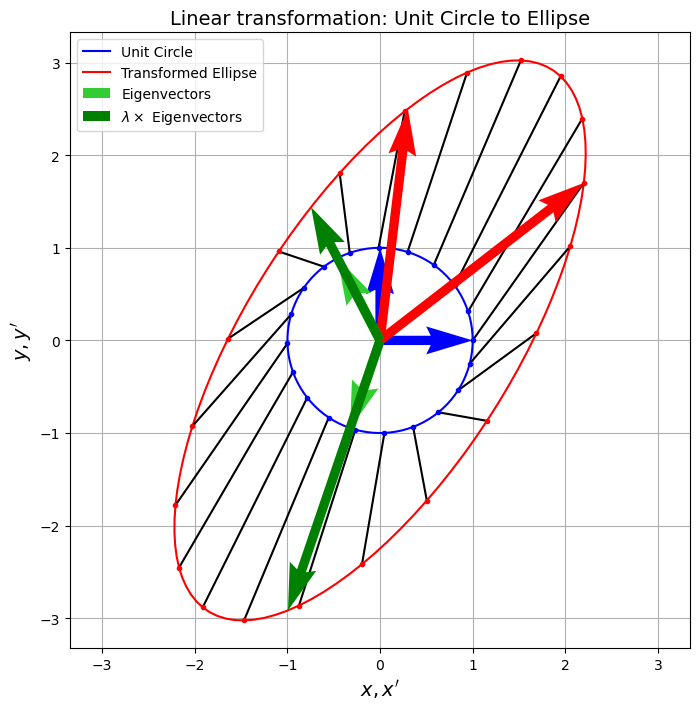

In [21]:

fig = plt.figure(figsize=(8, 8))
ax1 = fig.add_subplot(111)

# construct points on a circle parametrically
theta = np.linspace(0,2*np.pi,100) # runs from 0 to 2*pi, so the curve closes

# A 2xn array of points
points = np.vstack( (np.cos(theta), np.sin(theta)) )

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Linear transformation: Unit Circle to Ellipse', fontsize=14)
ax1.grid(True)

x_basis = np.array([1,0]) 
y_basis = np.array([0,1]) 

# plot the circle
ax1.plot(points[0,:], points[1,:], color='blue', label='Unit Circle')

# plot original basis vectors
ax1.quiver(x_basis[0], x_basis[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)
ax1.quiver(y_basis[0], y_basis[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)


# choose a transformation matrix
A = np.array([[2.2,0.3],[1.7,2.5]])

# Transform basis vectors and points
xp_basis = A@x_basis
yp_basis = A@y_basis
pointsp = A@points

# plot the transformed ellipse
ax1.plot(pointsp[0,:], pointsp[1,:], color='red', label='Transformed Ellipse')

# plot the transformed basis vectors
ax1.quiver(xp_basis[0], xp_basis[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10, width=0.015)
ax1.quiver(yp_basis[0], yp_basis[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10, width=0.015)

# plot a subset of vectors and how they transform
for i, angle in enumerate(theta[::5]):  # don't use all the angles
    #ax1.plot([0,points[0,5*i]],[0,points[1,5*i]],'k')
    ax1.plot([points[0,5*i],pointsp[0,5*i]],[points[1,5*i],pointsp[1,5*i]],'k')
    ax1.plot([points[0,5*i]],[points[1,5*i]],'b.')
    ax1.plot([pointsp[0,5*i]],[pointsp[1,5*i]],'r.')
    
    
# compute and plot eigenvectors (special directions)
lam, vecs = sl.eig(A)

# plot the unit eigenvectors (initial direction)
ax1.quiver(vecs[0,0].real, vecs[1,0].real, angles='xy', scale_units='xy', scale=1, color='limegreen', zorder=20, width=0.015)
ax1.quiver(vecs[0,1].real, vecs[1,1].real, angles='xy', scale_units='xy', scale=1, color='limegreen', zorder=20, width=0.015, label='Eigenvectors')

# plot the scaled eigenvectors (transformed direction)
ax1.quiver(lam[0].real*vecs[0,0].real, lam[0].real*vecs[1,0].real, angles='xy', scale_units='xy',
           scale=1, color='g', zorder=30, width=0.015)
ax1.quiver(lam[1].real*vecs[0,1].real, lam[1].real*vecs[1,1].real, angles='xy', scale_units='xy',
           scale=1, color='g', zorder=30, width=0.015, label=r'$\lambda \times$ Eigenvectors')


ax1.axis('equal')
ax1.legend()
plt.show()

The blue arrows are the original basis vectors, the red are what they transform to (the columns of $A$ here) - we've seen this sort of thing already. 


The blue dots show a subset of the points (at a finite resolution - `theta[::5]` in the code above "prunes" the number of points), showing how unit vectors or points on the initial unit circle (in blue) map to new locations indicated by the red dots with black lines in between clarifying the correspondence.


Note how  the new locations/vectors now map out a (non-unit) ellipse (some stretching and rotation has gone on).

Most vectors change **both direction and magnitude** under the transformation.

However, there are **special directions** (highlighted by the green arrows) where the transformation acts purely as a **scaling** – the direction remains unchanged.


## Eigenvectors and eigenvalues: the transformation's "natural axes"

These special directions are fundamental properties of the matrix $A$.

* A non-zero vector $\boldsymbol{v}$ is called an **eigenvector** of $A$ if applying the transformation $A$ only scales $\boldsymbol{v}$ by a factor $\lambda$, without changing its direction (a negative $\lambda$ reverses it).

* The scaling factor $\lambda$ is called the **eigenvalue** corresponding to $\boldsymbol{v}$.

Mathematically, this relationship is expressed as:

$$
A \boldsymbol{v} = \lambda \boldsymbol{v}
$$

<br>

Finding these eigenvalues and eigenvectors tells us crucial information about how the matrix transforms space. (We will discuss how to calculate them shortly).


<br>

Eigenvectors can be said to represent the "natural axes" of the linear transformation defined by $A$ because they are the directions that remain invariant (up to scaling) under that transformation.


Think about what happens when you multiply an arbitrary vector $\boldsymbol{x}$ by a matrix $A$. The resulting vector $A\boldsymbol{x}$ generally points in a different direction and has a different magnitude compared to $\boldsymbol{x}$. The transformation involves both rotation/shear and scaling.
However, for specific directions defined by the eigenvectors $\boldsymbol{v}$, the transformation is much simpler. The equation $A\boldsymbol{v} = \lambda\boldsymbol{v}$ tells us that when $A$ acts on an eigenvector $\boldsymbol{v}$, the resulting vector $A\boldsymbol{v}$ points in the exact same direction as $\boldsymbol{v}$. The only effect of the transformation along these special directions is pure scaling by the factor $\lambda$ (the eigenvalue). These directions are "natural" because they reveal the fundamental stretching or compressing actions of the transformation, disentangled from any additional rotation or shear. If you were to align your coordinate system with the eigenvectors (if a full set exists), the transformation $A$ would look like a simple scaling along each axis, represented by the diagonal matrix $\Lambda$. This makes the eigenvectors the most natural basis in which to analyze the action of $A$.





## The special case of symmetric matrices

When the matrix is symmetric (try yourself or see the second example in the supplementary material), these axes align with the major and minor axes of the resulting ellipse. 


## Transforming a vector vs. changing basis

It's important to distinguish between the actions of applying a transformation to a vector and changing the coordinate system (basis) used to describe that vector - both are very important tasks we may wish to perform, and both can be described by pre-multiplying the vector by an appropriate matrix.

### Applying a transformation

When we compute $\boldsymbol{p}' = A\boldsymbol{p}$, we are taking a point/vector $\boldsymbol{p}$ (whose coordinates are usually given relative to the standard basis $\boldsymbol{i}, \boldsymbol{j}$) and finding its **new location** $\boldsymbol{p}'$ after the transformation $A$ is applied, still described relative or with respect to (w.r.t.) the standard basis $\boldsymbol{i}, \boldsymbol{j}$. The point **moves**, we are transforming the vector.

### Changing the basis

However, sometimes we want to describe the **same, fixed point** $\boldsymbol{p}$ using a *different* set of basis vectors. 

Let the new basis vectors be the columns of a matrix $A_b$. 

So, instead of $\boldsymbol{p} = p_1 \boldsymbol{i} + p_2 \boldsymbol{j}$, we want to find new coordinates $(p'_1, p'_2)$ such that $\boldsymbol{p} = p'_1 (A_b\boldsymbol{i}) + p'_2 (A_b\boldsymbol{j})$.

Let $\boldsymbol{p}' = (p'_1, p'_2)^T$ be the coordinate vector in the new basis. Then the relationship is:
$$
I \boldsymbol{p} = A_b \boldsymbol{p}'
$$
where $I$ is the matrix whose columns are the standard basis vectors ($\boldsymbol{i}, \boldsymbol{j}$). 

To find the coordinates $\boldsymbol{p}'$ in the new basis, we can simply solve this linear system for $\boldsymbol{p}'$:
$$
\boldsymbol{p}' = A_b^{-1} \boldsymbol{p}
$$


Here, the point $\boldsymbol{p}$ **does not move**. We are just finding its address or description relative to a different coordinate system.

Here's an example to demonstrate this in action

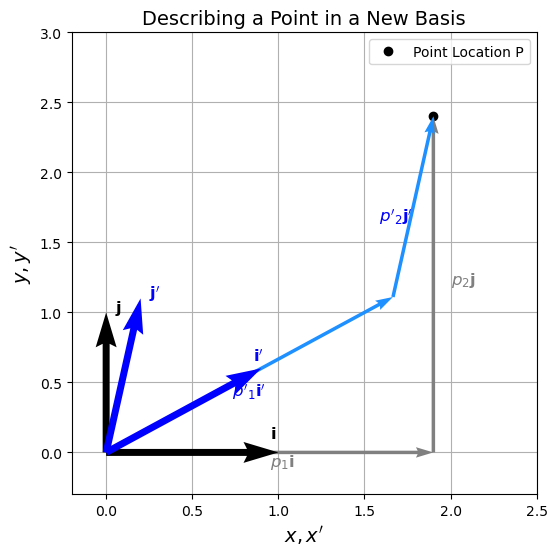

In [22]:
fig = plt.figure(figsize=(6, 6))

ax1 = fig.add_subplot(111)

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Describing a Point in a New Basis', fontsize=14)
ax1.grid(True)

# standard basis vectors
i_std = np.array([1,0])
j_std = np.array([0,1])

# plot the standard basis vectors
ax1.quiver(i_std[0], i_std[1], angles='xy', scale_units='xy', scale=1, color='k', zorder=10, width=0.015)
ax1.quiver(j_std[0], j_std[1], angles='xy', scale_units='xy', scale=1, color='k', zorder=10, width=0.015)
ax1.text(i_std[0]-0.05, i_std[1]+0.1, r"$\mathbf{i}$", fontsize=12)
ax1.text(j_std[0]+0.05,j_std[1], r"$\mathbf{j}$", fontsize=12)


# New basis matrix (columns are new basis vectors)
Ab = np.array([[0.9,0.2],[0.6,1.1]])

# New basis vectors i', j'
i_new = Ab@i_std
j_new = Ab@j_std

# plot the new basis vectors
ax1.quiver(i_new[0], i_new[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)
ax1.quiver(j_new[0], j_new[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10, width=0.015)
ax1.text(i_new[0]-0.05, i_new[1]+0.05, r"$\mathbf{i'}$", fontsize=12, color='blue')
ax1.text(j_new[0]+0.05,j_new[1], r"$\mathbf{j'}$", fontsize=12, color='blue')

# add a point p (coordinates in standard basis)
p_std_coords = np.array([1.9, 2.4])
p_location = p_std_coords[0]*i_std + p_std_coords[1]*j_std

# plot the point location
ax1.plot(p_location[0], p_location[1],'ko', label='Point Location P')

# plot components in standard basis
ax1.quiver(p_std_coords[0]*i_std[0], p_std_coords[0]*i_std[1], angles='xy', scale_units='xy', scale=1, color='grey', zorder=5)
ax1.quiver(p_std_coords[0]*i_std[0], p_std_coords[0]*i_std[1], p_std_coords[1]*j_std[0], p_std_coords[1]*j_std[1], angles='xy', scale_units='xy', scale=1,
           color='grey', zorder=5)
ax1.text(0.5*p_std_coords[0]*i_std[0], -0.1, r"$p_1 \mathbf{i}$", fontsize=12, color='grey')
ax1.text(p_std_coords[0]*i_std[0]+0.1, p_std_coords[0]*i_std[1]+0.5*p_std_coords[1]*j_std[1], r"$p_2 \mathbf{j}$", fontsize=12, color='grey')


# Calculate coordinates p' in the new basis
p_new_coords = sl.inv(Ab)@p_location

# plot components in the new basis (should reach the same point P)
ax1.quiver(p_new_coords[0]*i_new[0], p_new_coords[0]*i_new[1], angles='xy', scale_units='xy', scale=1, color='dodgerblue', zorder=6)
ax1.quiver(p_new_coords[0]*i_new[0], p_new_coords[0]*i_new[1], p_new_coords[1]*j_new[0], p_new_coords[1]*j_new[1], angles='xy', scale_units='xy', scale=1,
           color='dodgerblue', zorder=6)
ax1.text(0.5*p_new_coords[0]*i_new[0]-0.1, 0.5*p_new_coords[0]*i_new[1]-0.15, r"$p'_1 \mathbf{i'}$", fontsize=12, color='blue')
ax1.text(p_new_coords[0]*i_new[0]+0.5*p_new_coords[1]*j_new[0]-0.2, p_new_coords[0]*i_new[1]+0.5*p_new_coords[1]*j_new[1]-0.1, r"$p'_2 \mathbf{j'}$", fontsize=12, color='blue')

ax1.set_xlim(-0.2,2.5)
ax1.set_ylim(-0.3,3)
ax1.legend()
plt.show()

<div class="optional">
    
## Transformation with respect to a different basis [*]

Now, suppose we 

- have a transformation defined by matrix $A$ (relative to the standard basis) and we want to understand/analyse how this transformation acts on vectors, expressed in an original basis, or as may be more convenient how it acts on vectors expressed in terms of a *new basis* (defined by $A_b$), e.g. the natural basis defined above.

- **or**, suppose that we want to construct a linear transformation that achieves a given action on the vector, and that this transformation is easier to define in terms of a specific non-standard new basis.

<br>

Let $\boldsymbol{p}'$ be a vector representing the coordinates of a point w.r.t. a new basis $B$. 
    
To find the coordinates $\boldsymbol{q}'$ of the transformed point $A\boldsymbol{p}$ in the *same* new basis $B$, we follow these steps conceptually:

1.  **Convert to Standard Basis:** Find the coordinates $\boldsymbol{p}$ in the standard basis: $\boldsymbol{p} = A_b \boldsymbol{p}'$.
2.  **Apply Transformation:** Apply the transformation $A$ in the standard basis: $\boldsymbol{q} = A\boldsymbol{p} = A (A_b \boldsymbol{p}')$.
3.  **Convert Back to New Basis:** Convert the transformed point $\boldsymbol{q}$ back to coordinates relative to the new basis $B$: $\boldsymbol{q}' = A_b^{-1} \boldsymbol{q} = A_b^{-1} (A A_b \boldsymbol{p}')$.

So, the matrix $A'$ that directly transforms coordinates from $\boldsymbol{p}'$ to $\boldsymbol{q}'$ *within the new basis $B$* is:

$$
A' = A_b^{-1} A A_b
$$


This operation $A_b^{-1} A A_b$ is called a **similarity transform**. It tells us what the linear transformation $A$ "looks like" from the perspective of the new basis $B$.


This idea is most powerful when we choose the **eigenvectors** of $A$ as our new basis. If $P$ is the matrix whose columns are the eigenvectors of $A$, then the transformation matrix in the eigenbasis becomes $P^{-1}AP = \Lambda$, which is a **diagonal matrix**. This means that in the eigenbasis, the transformation $A$ simply becomes independent scaling along the coordinate axes, which greatly simplifies analysis. This is the core idea behind **matrix diagonalization**, which we explore next.

<br><br>

See the supplementary reading notebook for a more complete example of this.
    
</div>

# Eigenvalues and eigenvectors

In the previous lecture we were largely motivated by the solution of linear systems.

Another common task is finding the eigenvalues and eigenvectors for a given square $n\times n$ matrix $A$. (We will see some reasons why a bit later).

That is, find scalars $\lambda$ and corresponding non-zero vectors $\boldsymbol{v}$ such that

$$ A \boldsymbol{v} = \lambda \boldsymbol{v} $$

What is this achieving? 


- Mathematically: we can think of this as finding the directions $\boldsymbol{v}$ in $n$-dimensional space, where the action of $A$ applied to that direction is simply to scale it - the direction being unchanged.


- Geometrically: we saw examples of these vectors/directions in the two examples above.

## How to find eigenvalues and eigenvectors

Suppose we want to find the eigenvalues and eigenvectors of

$$ A = 
\left(
  \begin{array}{rr}
    3 & 1 \\
    1 & 3  
  \end{array}
\right)
$$

Well starting from 

\begin{align*}
A \boldsymbol{v} &= \lambda \boldsymbol{v}\\
\iff A \boldsymbol{v} - \lambda \boldsymbol{v} &= 0\\
\iff (A - \lambda I) \boldsymbol{v} &= 0
\end{align*}

If the matrix $A-\lambda I$ is invertible then the solution to this equation is clearly only $\boldsymbol{v}=\boldsymbol{0}$. 

We do *not* want this trivial solution.

We are looking for non-trivial solutions to this problem and so we want to find the $\lambda$ values that mean that
$A-\lambda I$ is *not* invertible.

Note that this only makes sense when $A$ is a square matrix. 

[For non-square matrices we can generalise this concept by introducing [*singular values*](https://en.wikipedia.org/wiki/Singular_value_decomposition) which we introduce later in this lecture (the SVD section) and which come up more in later modules on Inversion and Optimisation, and Machine Learning.].

## Projecting (onto eigenvectors)

These eigenvector directions $\boldsymbol{v}$ are often fundamental to understanding a system or dataset, representing the "natural axes" along which the transformation $A$ acts purely as a scaling. We frequently want to see how data looks when **projected** onto these special axes. Recall the concept of projection and the projection matrix $P = \boldsymbol{v}\boldsymbol{v}^T$ (for a unit vector $\boldsymbol{v}$) from the L2 homework ("projection matrix"). Projecting data onto eigenvectors is a key step in methods like Principal Component Analysis (PCA), allowing us to analyze the data along its principal directions of variation.

If you didn't get to look at that L2 exercise previously, would be good to try and do it now.

# The determinant again, and its use in finding eigenvalues

So for both linear systems (last lecture) and eigenvalues/vectors, we need a method to determine whether a given matrix is invertible or not - the determinant of the matrix tells us this as we covered in detail in the last lecture.

## An example eigenvalue problem

Consider again the eigenvalue problem for the matrix 

$$ A = 
\left(
  \begin{array}{rr}
    3 & 1 \\
    1 & 3  
  \end{array}
\right)
$$


As stated above, we are looking for non-trivial solutions to this problem and so we want to find the $\lambda$ values that mean that $A-\lambda I$ is *not* invertible, 

i.e. has zero determinant.

So we need to solve the equation

$$ \det (A - \lambda I) = 0$$

this boils down to a polynomial equation for which we want to find its [roots](http://mathworld.wolfram.com/PolynomialRoots.html) $\lambda$:

$$ 0 =  \det (A - \lambda I) = 
\left|
  \begin{array}{rr}
    3-\lambda & 1 \\
    1 & 3-\lambda  
  \end{array}
\right|
= (3-\lambda)^2 - 1 = \lambda^2 - 6\lambda + 8 = (\lambda-4)(\lambda-2)
$$

so the eigenvalues are

$$\lambda_1 = 4\quad\text{and}\quad \lambda_2 = 2$$

Note to do the final step I could see how to [factor](https://en.wikipedia.org/wiki/Factorization) the quadratic expression to find the roots, alternatively you could have used the formula for the roots of a quadratic (in this $2\times 2$ case).

Note that the polynomial $\det (A - \lambda I)$ is termed the [*characteristic polynomial*](https://en.wikipedia.org/wiki/Characteristic_polynomial) of $A$ - the eigenvalues are the roots of the characteristic polynomial.

You should be able to see that for an $n\times n$ matrix the characteristic polynomial will be of degree $n$ and hence we will be able to find $n$ roots (eigenvalues), but even if $A$ is a real matrix some of these eigenvalues may be complex (they will appear as complex conjugate pairs), and some may be repeated.

We can check our result against a SciPy function (`sl.eigvals`, see also `sl.eig`) to return the eigenvalues:

In [23]:
A = np.array([[3,1],[1,3]])
print("e'vals: ", sl.eigvals( A ))
# and if we know that the eigenvalues are real we can extract the real part:
print("Real(e'vals): ", np.real(sl.eigvals( A )))

e'vals:  [4.+0.j 2.+0.j]
Real(e'vals):  [4. 2.]


As we've found roots of a quadratic polynomial note that it's returned a complex number, in this case with the imaginary component being zero. 

We can therefore safely take only the real component and see that this agrees with our calculation.

Now let's find the eigenvectors.

Consider the first eigenvalue $\lambda_1 = 4$.

We want to find the vector $\boldsymbol{v}$ such that

$$A \boldsymbol{v} = \lambda \boldsymbol{v} \iff (A-\lambda I) \boldsymbol{v} =\boldsymbol{0}$$

which for our current example reads

$$
\left(
  \begin{array}{rr}
    3 & 1 \\
    1 & 3  
  \end{array}
\right)
\left(
  \begin{array}{r}
    v_1 \\
    v_2  
  \end{array}
\right)
  = 4
  \left(
  \begin{array}{r}
    v_1 \\
    v_2  
  \end{array}
\right)
$$

or 

$$
\left(
  \begin{array}{rr}
    -1 & 1 \\
    1 & -1  
  \end{array}
\right)
\left(
  \begin{array}{r}
    v_1 \\
    v_2  
  \end{array}
\right)
  = 
  \left(
  \begin{array}{r}
    0 \\
    0  
  \end{array}
\right)
$$

This clearly has the solution $v_1=v_2$ and emphasises the point that eigenvectors corresponding to a single eigenvalue are not unique - you can always multiply them by a (non-zero) constant (so their direction doesn't change, just their magnitude). 

It's common to fix the arbitrariness by normalising them, i.e. asking that 

$$\|\boldsymbol{v} \| = \sqrt{v_1^2+v_2^2} = 1$$

in which case we can say that $\boldsymbol{v}$ is a *unit vector*.

(NB. we will firm up our understanding of norms $\|\cdot\|$ a little later.)

Since we established that $v_1=v_2$, these two equations allow us to conclude that

$$\boldsymbol{v}_1 =   
\left(
  \begin{array}{r}
    \frac{1}{\sqrt{2}} \\
    \frac{1}{\sqrt{2}}  
  \end{array}
\right)
$$

As an exercise you can work out that second eigenvector - what relationship does it have with the first?

In [24]:
A = np.array([[3., 1.], [1.,3.]])
lam1 = 4
v1 = np.array([1./np.sqrt(2), 1./np.sqrt(2)])

print('v1 =', v1, '\n')

v2 = np.array([-v1[1], v1[0]])

print('v2 =', v2, '\n')

print(np.dot(v1,v2))

print(v1.dot(v2))

print(v1.dot(v1))
print(v2.dot(v2))

v1 = [0.707107 0.707107] 

v2 = [-0.707107  0.707107] 

0.0
0.0
0.9999999999999998
0.9999999999999998


And we can check the eigenvalues and eigenvectors we have calculated against SciPy (this time using `sl.eig` which returns the eigenvalues and the eigenvectors):

In [25]:
A = np.array([[3,1],[1,3]])
evals, evecs = sl.eig( A )
print(evals)
print(evecs)
print(evecs[:,0])
print(evecs[:,1])

[4.+0.j 2.+0.j]
[[ 0.707107 -0.707107]
 [ 0.707107  0.707107]]
[0.707107 0.707107]
[-0.707107  0.707107]


Let's verify by substituting what we've worked out back into the expression 

$$ A \boldsymbol{v} = \lambda \boldsymbol{v} $$

that our eigenvalues and eigenvectors are correct:

In [26]:
A = np.array([[3., 1.], [1.,3.]])

lam1 = 4
v1 = np.array([1./np.sqrt(2), 1./np.sqrt(2)])

print('A = \n', A, '\n')
print('v1 =', v1, '\n')
print('A@v1 = \n', A@v1, '\n')

# we can check if our result is (approximately) correct with
print('A @ v1 = lam1 * v1:  ', np.allclose(A@v1 , lam1*v1))

A = 
 [[3. 1.]
 [1. 3.]] 

v1 = [0.707107 0.707107] 

A@v1 = 
 [2.828427 2.828427] 

A @ v1 = lam1 * v1:   True


For symmetric matrices (as is the case here) it can be shown that eigenvectors corresponding to distinct eigenvalues are *orthogonal* to one another (and for a repeated eigenvalue they can be chosen to be orthogonal), and as a consequence linearly independent - this is not necessarily true for non-symmetric matrices as we will see below. (They are still not unique: any non-zero multiple of an eigenvector is also an eigenvector.)

As above we can scale them to be unit vectors (normalised).

If both are satisfied (orthogonal to one another, and all normalised) we say that the eigenvectors are [*orthonormal*](https://en.wikipedia.org/wiki/Orthonormality).

We can verify that they are of unit length by computing the Euclidean norm, or equivalently via the [dot product](https://en.wikipedia.org/wiki/Dot_product) of the vector with itself:

$$\|\boldsymbol{v}\|_2 = \sqrt{v_1^2 + v_2^2} = \sqrt{\boldsymbol{v} \cdot \boldsymbol{v}} = \sqrt{\boldsymbol{v}^T\boldsymbol{v}}$$

and so $||\boldsymbol{v}||_2 = 1 \iff \boldsymbol{v} \cdot \boldsymbol{v}=1 $, (in which case we call them unit vectors, or normalised vectors)


and they are orthogonal to one another via: 

$$\boldsymbol{v}_1 \cdot \boldsymbol{v}_2=0$$

Let's check these in a few different ways:

In [27]:
v1 = evecs[:,0]
v2 = evecs[:,1]
# check the dot product of vectors with themselves, in various ways!
print(v1.dot(v1))
print(v2.dot(v2))
print(np.dot(v1,v1))
print(v2.T@v2)
print(sl.norm(v2,2))

print('\n',v1.dot(v2))

0.9999999999999998
0.9999999999999998
0.9999999999999998
0.9999999999999998
0.9999999999999999

 0.0


## What does linear (in)dependence mean?

We covered this last lecture in the context of the solvability of linear systems. 

As a reminder (this time describing it in a more formal mathematical way compared to the previous lecture):

we say that a set of vectors $V:=\{\boldsymbol{v}_i\}$ are linearly independent if for all $(\forall)$ $\boldsymbol{v}_j \in V$ we *cannot* write it as a linear combination of the *other* vectors in $V$, 

i.e. we *cannot* find scalars $\alpha_i$ such that 

$$ \boldsymbol{v}_j = \sum_{i=1,i\neq j}^n \alpha_i \boldsymbol{v}_i$$

Equivalently, the vectors are linearly independent (*l.i.*) if the equation

$$\sum_{i=1}^n \alpha_i \boldsymbol{v}_i = \boldsymbol{0}$$

has *only the trivial solution*: $\alpha_i = 0$, $\forall i$.

Or the way we explained it in the previous lecture: $n$ vectors are *l.i.* if they span $n$-dimensional space - we can use a weighted sum of them to reach *any* point in that space.

## Repeated eigenvalues - algebraic & geometric multiplicity

Sometimes we will find the same eigenvalue repeated, for example:

In [28]:
A = np.array([[1,0],[0,1]])
evals, evecs = sl.eig( A )
print(evals)
print(evecs)
print(evecs[:,0].dot(evecs[:,0]))
print(evecs[:,1].dot(evecs[:,1]))
print(evecs[:,0].dot(evecs[:,1]))
v1 = evecs[:,0]
v2 = evecs[:,1]
print(v1)
print(v2)

[1.+0.j 1.+0.j]
[[1. 0.]
 [0. 1.]]
1.0
1.0
0.0
[1. 0.]
[0. 1.]


As $\lambda = 1$ appears twice we say it is an eigenvalue of **algebraic multiplicity** 2.

In this case we *are able* to find two orthogonal eigenvectors (as for this case the matrix is again symmetric) that correspond to this eigenvalue.

Since they are orthogonal they span a 2D space (called the **eigenspace**), and we say that the eigenvalue has **geometric multiplicity** 2 (the dimension of the corresponding eigenspace - which is the dimension of the nullspace of $A-\lambda I$ of course).

Let's consider another case:

In [29]:
A = np.array([[1,1],[0,1]])
evals, evecs = sl.eig( A )
print(evals)
print(evecs)
print(evecs[:,0].dot(evecs[:,0]))
print(evecs[:,1].dot(evecs[:,1]))
print(evecs[:,0].dot(evecs[:,1]))
v1 = evecs[:,0]
v2 = evecs[:,1]
print(v1)
print(v2)

[1.+0.j 1.+0.j]
[[ 1.000000e+00 -1.000000e+00]
 [ 0.000000e+00  2.220446e-16]]
1.0
1.0
-1.0
[1. 0.]
[-1.000000e+00  2.220446e-16]


In this case we do NOT have two linearly independent vectors - the eigenspace is only 1D.

Thus for this case while the eigenvalue's *algebraic multiplicity* is again 2,  the *geometric multiplicity* is only 1 - these two vectors only span a 1D space.

(So if you think about it the names *algebraic* and *geometric* multiplicity make perfect sense!)

## Some useful theoretical results about eigenvalues/vectors

We won't prove any of the following, but you could check by trying a few examples that the following appear to hold.



1. The eigenvalues of symmetric real matrices are *always real*.



2. Eigenvectors corresponding to distinct eigenvalues are always *linearly independent*. (For repeated eigenvalues we **may be able** to find the corresponding number of linearly independent eigenvectors).



3. The eigenvectors of a symmetric real matrix, corresponding to *distinct* eigenvalues, are mutually *orthogonal*.



4. A consequence of this is that, if a symmetric real matrix has all distinct eigenvalues, then 
    - the matrix of normalised (i.e. of unit length) eigenvectors is orthogonal: $P^TP = I$. (If we don't bother to normalise them first then $P^TP$ would instead be diagonal).
    - the normalised vectors form an *orthonormal basis* for $n$-dimensional Euclidean space.

<div class="optional">
    
## Symmetric Positive-Definite (SPD) matrices [*]

[Symmetric positive-definite](https://en.wikipedia.org/wiki/Definiteness_of_a_matrix) matrices appear all over the place, in physics as well as the result of numerical discretisation.

A symmetric matrix $A$ is said to be positive-definite if 

$$\boldsymbol{x}^T A \boldsymbol{x} >0 \qquad \forall \boldsymbol{x}\ne \boldsymbol{0} $$

One can show that a symmetric matrix is positive definite as well if and only if all of its eigenvalues are strictly positive.

Similar definitions exist for semi-definite, negative-definite etc.

Some properties of matrices such as these can be found here:
<https://en.wikipedia.org/wiki/Definiteness_of_a_matrix#Properties>


<br>

<br>

Recall the plot of a circle being transformed into an ellipse above (for a non-symmetric matrix). For a symmetric matrix - and so in particular an SPD matrix - the eigenvectors are aligned with the major and minor axes of the ellipse (see the SPD example in the supplementary notebook).

<br>

<br>

### Diagonal dominance

Other than checking that all eigenvalues are positive, another check that is useful for matrices we often see in practice is to check that the diagonal entries are positive, and that their entries make them [*strictly diagonally dominant*](https://en.wikipedia.org/wiki/Diagonally_dominant_matrix):

$$ |A_{ii}| >  \sum_{\substack{j=1\\ j\ne i}}^n \, |A_{ij}|, \;\;\;\;  i=1,2,\ldots, n.$$

For a symmetric matrix with positive diagonal entries, strict diagonal dominance *guarantees* positive definiteness (by [Gershgorin's circle theorem](https://en.wikipedia.org/wiki/Gershgorin_circle_theorem) every eigenvalue lies within $\sum_{j\ne i}|A_{ij}|$ of some $A_{ii}>0$), but it is not necessary: many SPD matrices are not diagonally dominant.

</div>

# Matrix diagonalisation

A further consequence/related concept is that a square $n \times n$ matrix $A$ with $n$ **distinct** eigenvalues is diagonalisable.

This means that we can find a matrix $P$ such that we decompose or factorize the matrix in the following way

$$A = P\Lambda P^{-1}$$

where $\Lambda$ is a diagonal matrix. 

Said another way, there exists a transformation matrix $P$ such that

$$P^{-1}AP\quad\text{is a diagonal matrix}$$

<br>

Note that the converse is not true - a matrix **may be** diagonalisable even if it does not have distinct eigenvalues, i.e. has repeated eigenvalues.

## Symmetric real matrices

In the special case of a symmetric real matrix, it can ***always*** *be diagonalised* using an [orthogonal matrix](https://en.wikipedia.org/wiki/Orthogonal_matrix):

$$A = Q\Lambda Q^T \quad \iff \quad \Lambda = Q^T A Q$$

A consequence is that any $n\times n$ real symmetric matrix must possess $n$ mutually orthogonal eigenvectors, even if it has repeated eigenvalues (so we actually have a stronger result than 4 above).

[Aside: The slight contradiction in this phrasing you may spot here is due to the fact that the eigenvectors corresponding to repeated eigenvalues, while chosen to be l.i. in order to span the corresponding eigenspace, won't be automatically orthogonal. However, we can construct or choose orthogonal eigenvectors - the [Gram-Schmidt process](https://en.wikipedia.org/wiki/Gram%E2%80%93Schmidt_process) is a method that can be used to achieve this].

   
##  Orthogonal Matrices: Rotations and Reflections 

Before moving on, let's formally define a special type of matrix that appeared in the diagonalization of symmetric matrices and will reappear shortly in the SVD: the **orthogonal matrix**.

An $n \times n$ square matrix $Q$ is called **orthogonal** if its columns (and rows) form an **orthonormal basis** for $\mathbb{R}^n$. This means each column vector has unit length (is normalized) and is orthogonal (perpendicular) to every other column vector.

Mathematically, this condition is equivalent to:

$$
Q^T Q = Q Q^T = I
$$

where $I$ is the $n \times n$ identity matrix.



### Properties and Geometric Interpretation

Orthogonal matrices have several crucial properties:

1.  **Inverse is the Transpose:** From the definition, it's clear that the inverse of an orthogonal matrix is simply its transpose:
    $$
    Q^{-1} = Q^T
    $$
    This is computationally very convenient, as transposing a matrix is much cheaper than computing a general inverse.

2.  **Preserves Lengths (Norms):** Multiplication by an orthogonal matrix preserves the Euclidean ($L_2$) norm of a vector:
    $$
    \|Q\boldsymbol{x}\|_2 = \|\boldsymbol{x}\|_2
    $$
    *Proof:* $\|Q\boldsymbol{x}\|_2^2 = (Q\boldsymbol{x})^T (Q\boldsymbol{x}) = \boldsymbol{x}^T Q^T Q \boldsymbol{x} = \boldsymbol{x}^T I \boldsymbol{x} = \boldsymbol{x}^T \boldsymbol{x} = \|\boldsymbol{x}\|_2^2$.

3.  **Preserves Angles (Dot Products):** Orthogonal matrices preserve the dot product between vectors:
    $$
    (Q\boldsymbol{x}) \cdot (Q\boldsymbol{y}) = \boldsymbol{x} \cdot \boldsymbol{y}
    $$
    *Proof:* $(Q\boldsymbol{x})^T (Q\boldsymbol{y}) = \boldsymbol{x}^T Q^T Q \boldsymbol{y} = \boldsymbol{x}^T I \boldsymbol{y} = \boldsymbol{x}^T \boldsymbol{y}$.

Because they preserve lengths and angles, orthogonal transformations correspond geometrically to **rotations**, **reflections**, or combinations thereof. They represent rigid motions that don't stretch or shear space.



### Relevance

As we just saw, the matrix $P$ (or $Q$) used to diagonalize a **symmetric real matrix** is always orthogonal ($A = Q\Lambda Q^T$). Furthermore, the $U$ and $V$ matrices in the **Singular Value Decomposition (SVD)** (see later; $A = U\Sigma V^T$) are also each orthogonal, representing the rotational components of the general linear transformation represented by $A$.
    

<div class="optional">

## When is a matrix diagonalisable? [\*]

An $n \times n$ matrix $A$ is diagonalisable if and only if for all eigenvalues the algebraic and geometric multiplicities are equal, equivalently the sum of the geometric multiplicities is $n$ - we'll see why in the next cell. 

This just means we need to be able to find $n$ linearly independent eigenvectors (even if some of the eigenvalues are repeated).

For more details see <https://en.wikipedia.org/wiki/Diagonalizable_matrix>.

What if we can't find $n$ l.i. eigenvectors? Then the [Jordan normal form](https://en.wikipedia.org/wiki/Jordan_normal_form)  is the best we can do, which is still useful for certain tasks.
    
</div>

<div class="optional">
    
### The details

Why do we need linearly independent eigenvectors?

Consider an $n\times n$ matrix $A$ with eigenvectors $\boldsymbol{v}_i$ and corresponding eigenvalues $\lambda_i$, $i=1,\ldots, n$.

Define $P$ to be the matrix of eigenvectors making up its columns:

$$P = \left[ \; \boldsymbol{v}_1 \;\;  \boldsymbol{v}_2  \; \; \cdots \; \;  \boldsymbol{v}_n \; \right]$$

and $\Lambda$ the diagonal matrix of eigenvalues:

$$\Lambda = \begin{pmatrix}
\lambda_1 & 0 &  \cdots & 0 \\
0 & \lambda_2 &  \ddots & 0\\
\vdots & &  \ddots  & \vdots \\
0 & \cdots & 0 & \lambda_n
\end{pmatrix}$$

Then based on what we've seen about matrix-vector multiplication several times already, i.e. it acts on the columns independently, we have

\begin{align*}
AP & = A \left[ \; \boldsymbol{v}_1 \;\;  \boldsymbol{v}_2  \; \; \cdots \; \;  \boldsymbol{v}_n \; \right] \\[5pt]
& = \left[ \;  \lambda_1\boldsymbol{v}_1 \;\;   \lambda_2\boldsymbol{v}_2  \; \; \cdots \; \;  \lambda_n\boldsymbol{v}_n \; \right] \\[15pt]
& = \left[ \; \boldsymbol{v}_1 \;\;  \boldsymbol{v}_2  \; \; \cdots \; \;  \boldsymbol{v}_n \; \right]
\begin{pmatrix}
\lambda_1 & 0 &  \cdots & 0 \\
0 & \lambda_2 &  \ddots & 0\\
\vdots & &  \ddots  & \vdots \\
0 & \cdots & 0 & \lambda_n
\end{pmatrix}\\[15pt]
& = P
\begin{pmatrix}
\lambda_1 & 0 &  \cdots & 0 \\
0 & \lambda_2 &  \ddots & 0\\
\vdots & &  \ddots  & \vdots \\
0 & \cdots & 0 & \lambda_n
\end{pmatrix}
\end{align*}

<br>

This is good, but to finish things and to obtain the diagonalisation we are reliant on $P$ being invertible. 

$P$ is the matrix of eigenvectors. 

$P$ is therefore invertible (and we thus have a diagonalisation of the matrix) if and only if the eigenvectors are linearly independent. This is one of the equivalent properties of a matrix being invertible that we saw earlier.

In which case we post-multiply both sides by $P^{-1}$:

\begin{align*}
AP = P \Lambda \implies A = P \Lambda P^{-1}
\end{align*}

</div>

<div class="optional">
    
### An example

Let's consider the problem from above
    
$$ A = 
\left(
  \begin{array}{rr}
    3 & 1 \\
    1 & 3  
  \end{array}
\right)
$$
    
use the eigenvalues and eigenvectors we found to construct $P$ and $\Lambda$ and check that their combination is indeed equal to $A$:
    
</div>

In [30]:
A = np.array([[3., 1.], [1.,3.]])
lam1 = 4
# use the normalised, i.e. unit length e-vecs
v1 = np.array([1./np.sqrt(2), 1./np.sqrt(2)])
lam2 = 2
v2 = np.array([-v1[1],v1[0]])

# force v1 and v2 to be column vecs
v1 = v1.reshape(2,1)
v2 = v2.reshape(2,1)

# and stack them into the matrix P
P = np.hstack((v1,v2))
# and form the diagonal matrix with e'vals on the main diagonal
Lambda = np.diag(np.array([lam1,lam2]))
print(P)
print(Lambda)
# we can check if our result is (approximately - read the docs) correct with
print(r'A = P \Lambda P^{-1}:  ', np.allclose(A , P@Lambda@(sl.inv(P))))
print(r'A = P \Lambda P^T:  ', np.allclose(A , P@Lambda@((P.T))))

[[ 0.707107 -0.707107]
 [ 0.707107  0.707107]]
[[4 0]
 [0 2]]
A = P \Lambda P^{-1}:   True
A = P \Lambda P^T:   True


Now let's check how we can form the diagonalisation using the outputs from `sl.eig`.

In [31]:
lam, vecs = sl.eig(A)
print(lam)
print(vecs)
print('The P we constructed is the same matrix you get from sl.eig:', np.allclose(P , vecs))
print('The diagonal Lambda matrix we constructed is the same matrix you get from sl.eig:', np.allclose(Lambda , lam))
print(' Our Lambda matrix = \n ',Lambda)
print('sl.eig returns for eigenvalues: ',lam)
# ah we forgot that eig returns complex numbers even when real, so instead let's check
print('The diagonal Lambda matrix we constructed is the same matrix you get via np.diag(np.real(lam)):', 
      np.allclose(Lambda , np.diag(np.real(lam))))
# and therefore now
print('A =  vecs@np.diag(np.real(lam))@sl.inv(vecs)) :', np.allclose(A, vecs@np.diag(np.real(lam))@sl.inv(vecs)))

[4.+0.j 2.+0.j]
[[ 0.707107 -0.707107]
 [ 0.707107  0.707107]]
The P we constructed is the same matrix you get from sl.eig: True
The diagonal Lambda matrix we constructed is the same matrix you get from sl.eig: False
 Our Lambda matrix = 
  [[4 0]
 [0 2]]
sl.eig returns for eigenvalues:  [4.+0.j 2.+0.j]
The diagonal Lambda matrix we constructed is the same matrix you get via np.diag(np.real(lam)): True
A =  vecs@np.diag(np.real(lam))@sl.inv(vecs)) : True


## A geometrical interpretation of matrix multiplication using matrix diagonalisation 

Recall the example from above for how multiplication by a matrix 
    
````A = np.array([[2.2,0.3],[1.7,2.5]])````
    
transformed the unit circle.
    
Let's understand that transformation in terms of the matrix diagonalisation.
    
In this case $A$ is not symmetric. A homework exercise considers a case where $A$ is symmetric.
    

lam =  [1.620274+0.j 3.079726+0.j]
vecs =  [[-0.459594 -0.322764]
 [ 0.888129 -0.946479]]


(-2.441768, 2.442281, -3.325370, 3.324818)

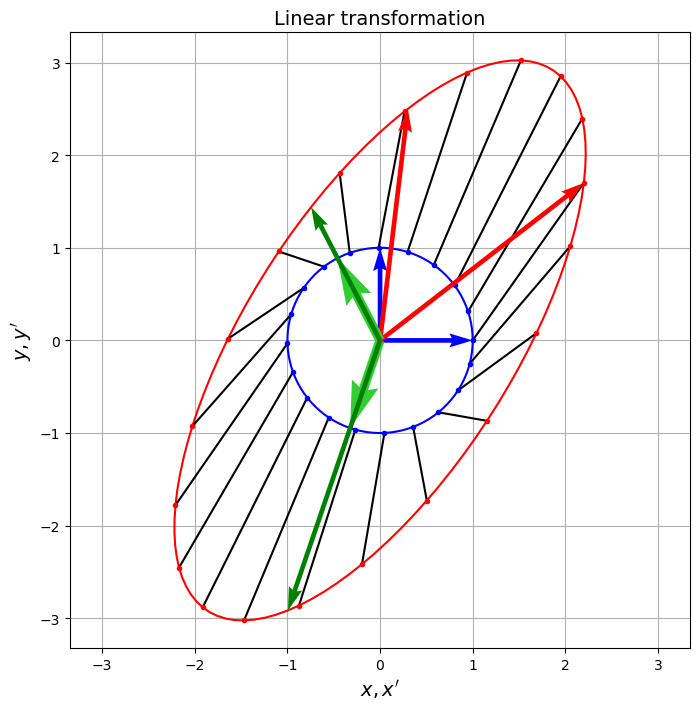

In [32]:
# First repeat the full transformation from above

fig = plt.figure(figsize=(8, 8))
ax1 = fig.add_subplot(111)

# construct points on a circle parametrically
theta = np.linspace(0,2*np.pi,100) # runs from 0 to 2*pi, so the curve closes

# A 2xn array of points
points = np.vstack( (np.cos(theta), np.sin(theta)) )

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Linear transformation', fontsize=14)
ax1.grid(True)

x = np.array([1,0])
y = np.array([0,1])

# plot the circle
ax1.plot(points[0,:], points[1,:], color='blue')

# plot some vectors
ax1.quiver(x[0], x[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10)
ax1.quiver(y[0], y[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10)


# choose a random transformation matrix
A = np.array([[2.2,0.3],[1.7,2.5]])

xp = A@x
yp = A@y
pointsp = A@points

# plot the transformed circle
ax1.plot(pointsp[0,:], pointsp[1,:], color='red')

# plot the transformed vectors
ax1.quiver(xp[0], xp[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10)
ax1.quiver(yp[0], yp[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10)

# plot a subset of vectors and how they transform
for i, angle in enumerate(theta[::5]):  # don't use all the angles
    #ax1.plot([0,points[0,5*i]],[0,points[1,5*i]],'k')
    ax1.plot([points[0,5*i],pointsp[0,5*i]],[points[1,5*i],pointsp[1,5*i]],'k')
    ax1.plot([points[0,5*i]],[points[1,5*i]],'b.')
    ax1.plot([pointsp[0,5*i]],[pointsp[1,5*i]],'r.')

# compute and plot some special directions!
lam, vecs = sl.eig(A)

print('lam = ', lam)
print('vecs = ', vecs)

# plot the unit eigenvectors
ax1.quiver(vecs[0,0], vecs[1,0], angles='xy', scale_units='xy', scale=1, color='limegreen', zorder=20, width=0.015)
ax1.quiver(vecs[0,1], vecs[1,1], angles='xy', scale_units='xy', scale=1, color='limegreen', zorder=20, width=0.015)

# plot the scaled eigenvectors
ax1.quiver(np.real(lam[0])*vecs[0,0], np.real(lam[0])*vecs[1,0], angles='xy', scale_units='xy', 
           scale=1, color='g', zorder=30)
ax1.quiver(np.real(lam[1])*vecs[0,1], np.real(lam[1])*vecs[1,1], angles='xy', scale_units='xy', 
           scale=1, color='g', zorder=30)

ax1.axis('equal')


The blue arrows are the original basis vectors, the red are what they transform to (the columns of $A$ here) - we've seen this sort of thing already. 


The blue dots show a subset of the points (at a finite resolution - `theta[::5]` in the code above "prunes" the number of points), showing how unit vectors or points on the initial unit circle (in blue) map to new locations indicated by the red dots with black lines in between clarifying the correspondence.

Note how  the new locations/vectors now map out a (non-unit) ellipse (some stretching and rotation has gone on).

The green arrows indicate the *special* vectors/directions that do not change their orientation, only their magnitude. These are clearly the eigenvectors.

<br>

Let's use matrix diagonalisation to break up this single transformation into three:



    
By noting that 

\begin{align*}
A = P \Lambda P^{-1} 
\end{align*}

where 

$$P = \left[ \; \boldsymbol{v}_1 \;\;  \boldsymbol{v}_2  \; \; \cdots \; \;  \boldsymbol{v}_n \; \right]$$

and 

$$\Lambda = \begin{pmatrix}
\lambda_1 & 0 &  \cdots & 0 \\
0 & \lambda_2 &  \ddots & 0\\
\vdots & &  \ddots  & \vdots \\
0 & \cdots & 0 & \lambda_n
\end{pmatrix}$$

let's break down the single matrix multiplication $A\boldsymbol{x}$ which performed the above transformation of the unit circle into three multiplications taken in turn:

<br>

\begin{align*}
A\boldsymbol{x} = P \Lambda P^{-1}\boldsymbol{x} = P \; (\Lambda\;  (P^{-1}\boldsymbol{x}))
\end{align*}


In [33]:
A = np.array([[2.2,0.3],[1.7,2.5]])

# its eigenvalues and eigenvectors - printed out above - you can check yourself
lam1 = 3.079726
v1 = np.array([0.322764, 0.946479])
lam2 = 1.620274
v2 = np.array([-0.459594,0.888129])

# normalise the eigenvectors
v1 = v1/np.sqrt(np.dot(v1,v1))
v2 = v2/np.sqrt(np.dot(v2,v2))
               
# in order to form the matrix P, first force v1 and v2 to be column vecs
v1 = v1.reshape(2,1)
v2 = v2.reshape(2,1)

# and stack them into the matrix P using hstack
P = np.hstack((v1,v2))
# and form the diagonal matrix with e'vals on the main diagonal
Lambda = np.diag(np.array([lam1,lam2]))

# confirm our diagonalisation works
print('A =  P@Lambda@sl.inv(P) :', np.allclose(A, P@Lambda@sl.inv(P)))
print(P)
print(Lambda)
print(sl.inv(P))

A =  P@Lambda@sl.inv(P) : True
[[ 0.322764 -0.459594]
 [ 0.946479  0.888129]]
[[3.079726 0.      ]
 [0.       1.620274]]
[[ 1.230688  0.636863]
 [-1.311544  0.447257]]



First let's plot what the first multiplication

$$P^{-1}\boldsymbol{x}$$

does to the unit circle:


(-1.524246, 1.523616, -1.524172, 1.523972)

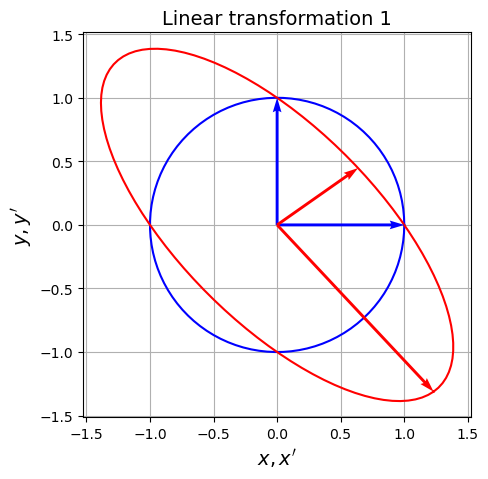

In [34]:
fig = plt.figure(figsize=(5, 5))
ax1 = fig.add_subplot(111)

# construct points on a circle parametrically
theta = np.linspace(0,2*np.pi,100) # runs from 0 to 2*pi, so the curve closes

# A 2xn array of points
points = np.vstack( (np.cos(theta), np.sin(theta)) )

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Linear transformation 1', fontsize=14)
ax1.grid(True)

x = np.array([1,0])
y = np.array([0,1])

# plot the circle
ax1.plot(points[0,:], points[1,:], color='blue')

# plot some vectors
ax1.quiver(x[0], x[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10)
ax1.quiver(y[0], y[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10)


# Use our P^{-1} matrix

xp = sl.inv(P)@x
yp = sl.inv(P)@y
pointsp = sl.inv(P)@points

# plot the transformed circle
ax1.plot(pointsp[0,:], pointsp[1,:], color='red')

# plot the transformed vectors
ax1.quiver(xp[0], xp[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10)
ax1.quiver(yp[0], yp[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10)

ax1.axis('equal')


From above $P^{-1}$ is

$$\begin{pmatrix} 
1.230688 & 0.636863 \\
-1.311544 & 0.447257
\end{pmatrix}$$

and so $(1,0)$ transforms to $(1.230688,-1.311544)$ and similarly for the second unit vector transforming to the second column of $P^{-1}$. Although difficult to see initially from the plot, notice that the two new red arrows are not orthogonal to one another.

Note that in the special case of a symmetric matrix $A$, $P$ is orthogonal and so this process we are mid way through here has a simpler interpretation - the $P$ and $P^{-1}$ matrices just perform rotations (or reflections). See a homework exercise for this case.

<br>

Now let's pre-multiply by $\Lambda$:


(-4.694260, 4.692320, -2.469576, 2.469251)

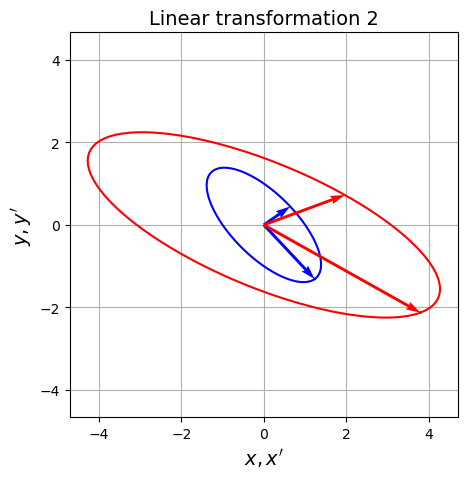

In [35]:
# before running this cell please make sure you run the previous

fig = plt.figure(figsize=(5, 5))
ax1 = fig.add_subplot(111)

# Use the points and the x,y from the previous cell:
x = xp
y = yp
points = pointsp

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Linear transformation 2', fontsize=14)
ax1.grid(True)

# plot the circle
ax1.plot(points[0,:], points[1,:], color='blue')

# plot some vectors
ax1.quiver(x[0], x[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10)
ax1.quiver(y[0], y[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10)

# Now use our Lambda matrix

xp = Lambda@x
yp = Lambda@y
pointsp = Lambda@points

# plot the transformed circle
ax1.plot(pointsp[0,:], pointsp[1,:], color='red')

# plot the transformed vectors
ax1.quiver(xp[0], xp[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10)
ax1.quiver(yp[0], yp[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10)

ax1.axis('equal')


The blue here was the outcome of the first operation, the red the new result.

So pre-multiplication by the diagonal $\Lambda$ just stretches by differing amounts in the $x$ and $y$ directions.

<br>

Finally we need to pre-multiply by $P$:



(-4.694260, 4.692320, -3.325370, 3.324818)

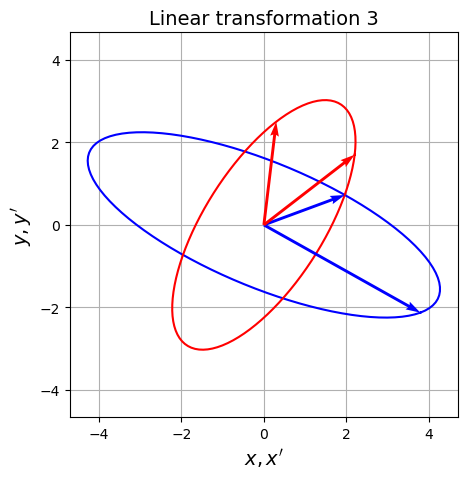

In [36]:
# before running this cell please make sure you run the previous

fig = plt.figure(figsize=(5, 5))
ax1 = fig.add_subplot(111)

# Use the points and the x,y from the previous cell:
x = xp
y = yp
points = pointsp

ax1.set_xlabel("$x, x'$", fontsize=14)
ax1.set_ylabel("$y, y'$", fontsize=14)
ax1.set_title('Linear transformation 3', fontsize=14)
ax1.grid(True)

# plot the circle
ax1.plot(points[0,:], points[1,:], color='blue')

# plot some vectors
ax1.quiver(x[0], x[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10)
ax1.quiver(y[0], y[1], angles='xy', scale_units='xy', scale=1, color='b', zorder=10)

# Now use our P matrix

xp = P@x
yp = P@y
pointsp = P@points

# plot the transformed circle
ax1.plot(pointsp[0,:], pointsp[1,:], color='red')

# plot the transformed vectors
ax1.quiver(xp[0], xp[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10)
ax1.quiver(yp[0], yp[1], angles='xy', scale_units='xy', scale=1, color='r', zorder=10)

ax1.axis('equal')

Again the blue was the output from the previous operations, and red the output from the final pre-multiplication.

Note that (as long as you run the three cells in order!) the red result here agrees with the transformation under the matrix $A$ that we plotted all in one go at the start.

<br>

As already said, in the case of a ***symmetric matrix*** the $P$ and thus $P^{-1}$ being ***orthogonal matrices means that they just correspond to simple rotations (or reflections)***. In the case where we start from a symmetric matrix therefore the above three operations are easier to interpret - see homework for a worked example.
    
While for non-symmetric cases we can't interpret matrix multiplication as simply as rotation, scaling then the inverse rotation, as we can for symmetric matrices. The SVD (below) gives us a way of interpreting any matrix as first rotation, scaling, a second rotation that isn't the inverse of the first.


# Some applications of eigen-values/vectors

Note that a number of applications of linear algebra, eigenvalues, matrix diagonalisation etc are covered in the supplementary reading notebook. In particular, their use in the solution of systems of ODEs.

# Singular Value Decomposition (SVD) 


We've seen that **eigendecomposition** ($A = P\Lambda P^{-1}$) is incredibly useful for understanding ***square*** matrices by revealing their "natural axes" (eigenvectors) and scaling factors (eigenvalues).

<br> 

But what about the matrix-vector multiplication $  A\boldsymbol{x}  $ in the case of $A$ 

- being square, but not being diagonalisable, or

- being an $m\times n$ matrix?

In the latter case, for a given $n\times 1$ vector $\boldsymbol{x}\;$ this linear transformation maps it to a new $m\times 1$ vector, i.e. matrix multiplication in this non-square case maps vectors or points from $\mathbb{R}^n$ into $\mathbb{R}^m$. This action could increase or **reduce** the dimension of the data contained in the vector.


<br>

The **Singular Value Decomposition (SVD)** provides the answer:  ***any*** $m \times n$ matrix $A$ can be factored into the product of three specific matrices:

$$
A = U\Sigma V^{T}
$$


<br>

* **$U$**: An $m \times m$ **orthogonal matrix** ($U^T U = I_m$). Its columns are called the **left singular vectors** and form an orthonormal basis for the output space ($\mathbb{R}^m$). They are the eigenvectors of $AA^T$.


* **$V$**: An $n \times n$ **orthogonal matrix** ($V^T V = I_n$). Its columns are called the **right singular vectors** and form an orthonormal basis for the input space ($\mathbb{R}^n$). They are the eigenvectors of $A^TA$. 


* **$\Sigma$**: An $m \times n$ **diagonal matrix**. Its diagonal entries $\sigma_1, \sigma_2, \ldots, \sigma_p$ (where $p = \min(m, n)$) are the **singular values** of $A$. They are non-negative and conventionally ordered $\sigma_1 \ge \sigma_2 \ge \ldots \ge \sigma_p \ge 0$. All off-diagonal entries of $\Sigma$ are zero. 


The singular values are the square roots of the eigenvalues of the square matrix $A^TA$.  They are also the square roots of the eigenvalues of the square matrix $AA^T$.  


But hang on .....  if $A$ is non-square then $A^TA$ and $AA^T$ are of different size and thus have different numbers of eigenvalues - how to reconcile this apparent contradiction? -> The extra eigenvalues are always zero, i.e. the *maximum* number of non-zero singular values is the smaller of $m$ and $n$.



<br>


Think of SVD as revealing the most important **directions** and **scaling factors** associated with *any* linear transformation.




*(Figure: https://en.wikipedia.org/wiki/Singular_value_decomposition#/media/File:Singular_value_decomposition_visualisation.svg)*

<img src="./figures/Singular_value_decomposition_visualisation.svg" width=400px>


replace the star with transpose in the case of real-valued matrices, which we will consider here.




## Geometric interpretation: rotation -> scaling -> rotation

The SVD provides us with a geometric interpretation of what *any* matrix multiplication $A\boldsymbol{x}$ does.


Recall that  $A\boldsymbol{x}$ can be interpreted as $ U (\Sigma (V^{T}\boldsymbol{x}))$, and hence the transformation to the vector $\boldsymbol{x}$ can be broken down as

<br>

1.  **Rotation/Reflection ($V^T$):** Since $V$ is orthogonal, $V^T$ (=$V^{-1}$) is also orthogonal. It rotates or reflects the input vector $\boldsymbol{x}$ without changing its length. Refer back to the start of this lecture ($\boldsymbol{p}' = A_b^{-1} \boldsymbol{p}$) - multiplying $\boldsymbol{x}$ by $V^T$ rotates/reflects $\boldsymbol{x}$ (or equivalently performs a change of basis) so that its components are expressed in the coordinate system defined by the directions given by the columns of $V$ (the right singular vectors). 
(The vector is now "aligned" with the axes along which the overall transformation $A$ primarily acts as a scaling operation - to be performed next - calculation of the right singular vectors has found these axes for us.)

<br>

2.  **Scaling ($\Sigma$):** The diagonal matrix $\Sigma$ scales the components of the rotated vector along the standard coordinate axes by the singular values $\sigma_i$. Since it acts on $V^{T}\boldsymbol{x}$, this scaling happens along those specific directions.
If $m \neq n$, it also handles the ***change in dimension*** by embedding the result in the higher dimension or projecting it to the lower dimension via zero-padding or truncation.

<br>

3.  **Rotation/Reflection ($U$):** The orthogonal matrix $U$ rotates or reflects the scaled vector in the final output space, aligning it with the principal axes defined by the left singular vectors (columns of $U$).

<br>


Essentially, *any* linear map transforms a unit sphere (or circle) in the input space into a hyperellipsoid (or ellipse) in the output space. The singular values $\sigma_i$ give the lengths of the principal semi-axes of this resulting ellipsoid, and the columns of $U$ give their directions.


<br>

An example of a $3\times 2$, i.e. mapping $\mathbb{R}^2$ into $\mathbb{R}^3$ is given in the homework, also a $3\times 4$ case. Going through these examples should help clarify these sequences of transformations.



## The compact form of SVD

If both $A^TA$ and $AA^T$ are singular, then some of the singular values will be zero.

Let us suppose that there are $r$ non-zero singular values ($r$ is in fact the rank of $A$).

$A$ can then also be decomposed in a more compact (or reduced) form using only the singular vectors that correspond to non-zero singular values:

$$A = U_r\Sigma_r V_r^{T}$$

where


- $U_r$ is an $m\times r$ matrix with orthonormal columns ($U_r^TU_r = I_r$), which are the eigenvectors of the matrix $AA^T$ with non-zero eigenvalues,


- $V_r$ is an $n\times r$ matrix with orthonormal columns ($V_r^TV_r = I_r$), which are the eigenvectors of the matrix $A^TA$ with non-zero eigenvalues,


- $\Sigma_r$ is an $r\times r$ diagonal matrix whose diagonal entries, $\sigma_1, \sigma_2, \ldots , \sigma_r>0$  are the non-zero *singular values* of $A$

<br>

Here we just don't bother storing those entries which due to the zero singular values never contribute to the multiplication.


## Aside: some of the various uses of the SVD

    
1. This geometrical interpretation demonstrates how we can use the SVD to appreciate the most important direction of uncertainty/noise in observations - important in that they can have large or small impact on the model parameters we arrive at when doing inversion.  In  a very high dimensional system, if we wanted to perturb our model parameters (e.g. the initial state of the atmosphere in a weather forecast), then we can't afford to run lots of forecasts (termed an ensemble) where we fully explore the uncertainty, instead we might perturb the model parameters in the directions associated with the largest singular values.  Take a look at the homework exercise that demonstrates this by plotting scaled singular vectors.
For more on this in the context of weather forecasting see: [Singular vectors in atmospheric sciences: A review](https://www.sciencedirect.com/science/article/pii/S0012825212000657)



2. Since we can interpret an image as a matrix, a fun application of SVD is in image compression.  Notice first that expanding out the SVD:
$$A = U\Sigma V^{T} = \sigma_1 u_{:1} v_{:1}^T +  \sigma_2 u_{:2} v_{:2}^T + \ldots $$
since the $\sigma$'s are ordered in terms of their magnitudes, if we truncate this expansion early we get a so-called [low rank approximation](https://en.wikipedia.org/wiki/Low-rank_approximation) to the original matrix, or if we interpret the matrix as an image, we get different levels of compressed image! See <https://medium.com/@rameshputalapattu/jupyter-python-image-compression-and-svd-an-interactive-exploration-703c953e44f6>



### Principal Component Analysis (PCA)


3. The SVD is very important in related fields, e.g. see a description of its importance in Machine Learning and Data Science (in the context of PCA - principal component analysis) in the following links:



* <https://medium.com/@jonathan_hui/machine-learning-singular-value-decomposition-svd-principal-component-analysis-pca-1d45e885e491>


* [PCA for Dummies](https://web.archive.org/web/20251102031339/https://www.billconnelly.net/?p=697) (archived copy)
    
    
* <https://georgemdallas.wordpress.com/2013/10/30/principal-component-analysis-4-dummies-eigenvectors-eigenvalues-and-dimension-reduction/>
       
    
* <https://math.stackexchange.com/questions/3869/what-is-the-intuitive-relationship-between-svd-and-pca>
    
    
* [A Tutorial on Principal Component Analysis](https://arxiv.org/pdf/1404.1100.pdf)
    

* https://stats.stackexchange.com/questions/134282/relationship-between-svd-and-pca-how-to-use-svd-to-perform-pca
    
    
* https://stats.stackexchange.com/questions/2691/making-sense-of-principal-component-analysis-eigenvectors-eigenvalues/
    
    
    
<br>

The singular vectors in $U$ and $V$ provide orthonormal bases for the output and input spaces, respectively. In dimension reduction techniques like Principal Component Analysis (PCA), which is closely related to SVD, we often **project** the original high-dimensional data onto the lower-dimensional subspace spanned by the first few right singular vectors (columns of $V$) corresponding to the largest singular values. This projection uses the concepts and projection matrices ($P = \boldsymbol{v}\boldsymbol{v}^T$ or $P = \sum \boldsymbol{v}_i\boldsymbol{v}_i^T$ for projection onto a subspace spanned by orthonormal $\boldsymbol{v}_i$) introduced in the L2 homework ("projection matrix"). By doing so, we retain the directions of maximum variance in the data while reducing its dimensionality.

<br>
    
We'll return to PCA in lecture 8 (Probability & ML) in particular in a homework exercise, and you'll see it again in later modules. 
    


# Summary
    
- In this lecture we went further in understanding matrices from a geometric perspective. 


- This led us on to eigenvalues/vectors - we considered some theory and some applications, including matrix diagonalisation and how these concepts are useful in the analysis and solution of systems of ODEs.


- We introduced the Singular Value Decomposition as a generalisation of the eigen-decomposition of a square matrix.


- We went over some non-trivial examples, for fun and to further extend our coding experience.


- We touched on the use of (in the supplementary notebook) powerful in-built SciPy ODE solvers (`solve_ivp`).

